# Cas de référence : échantillon monolithique

Nom de la campagne : 
- `campagne_honey`
- `campagne_honey_CC`

## Mapping sans CC en fct de theta et la taille du motif

In [1]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
from math import *

campagnes = ['campagne_honey']
# Can be long the first time
data = get_bulk_data(read_data_from_campaigns(campagnes))

Lecture des données réalisée en 0.44477s


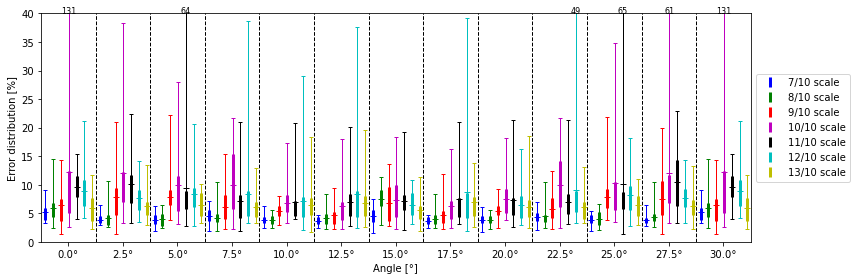

In [2]:
plot_map_theta_size(data, (12, 7, 10, 5),eoi=(0,3), angle_max=30.0, ymax=40)

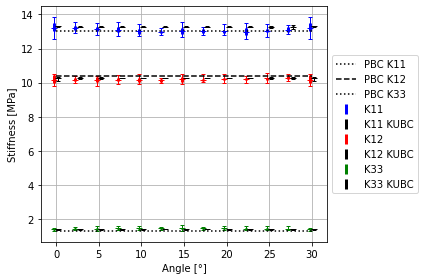

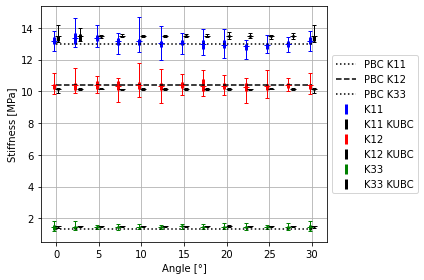

In [3]:
data_scale_7 = get_tests_by_test_id(data, index=1, target='7')
data_scale_8 = get_tests_by_test_id(data, index=1, target='8')
data_scale_9 = get_tests_by_test_id(data, index=1, target='9')
data_scale_10 = get_tests_by_test_id(data, index=1, target='10')
data_scale_11 = get_tests_by_test_id(data, index=1, target='11')
data_scale_12 = get_tests_by_test_id(data, index=1, target='12')
data_scale_13 = get_tests_by_test_id(data, index=1, target='13')
plot_coef_matrix_per_angle(data_scale_7, (12, 7, 10, 5), angle_max=30.0)
plot_coef_matrix_per_angle(data_scale_13, (12, 7, 10, 5), angle_max=30.0)


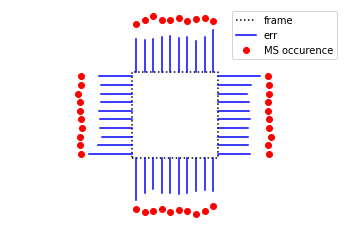

In [4]:
def plot_err_per_MS(data: dict[Test], eoi: tuple = (0, 3), factor: tuple = (20,20)):
    plt.figure()
    plt.axis('equal')
    plt.plot([], [], 'k:', label='frame')
    plt.plot([], [], 'b', label='err')
    plt.plot([], [], 'ro', label='MS occurence')
    plt.legend()
    # * plot the square shape of the machine
    plt.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], 'k:')
    mean_err = np.zeros((4, 10))
    counter_err = np.zeros((4, 10))
    for _, test in data.items():
        mean_err = mean_err+test.global_err[eoi[0]][eoi[1]]*test.get_MS()
        counter_err = counter_err+test.get_MS()
    mean_err = mean_err/counter_err
    mean_err=1*mean_err/np.max(mean_err)
    counter_err = counter_err/len(data)
    counter_err=1.3*counter_err/np.max(counter_err)
    for cote in range(4):
        for cyl in range(10):
            if cote % 2 == 0:
                plt.plot([-0.9+cyl/5]*2, [-1+cote, (-1+cote)
                                          * (1+mean_err[cote, cyl])], 'b')
                plt.plot([-0.9+cyl/5], [(-1+cote) *
                                        (1+counter_err[cote, cyl])], 'ro')
            else:
                plt.plot([2-cote, (2-cote)*(1+mean_err[cote, cyl])],
                         [-0.9+cyl/5]*2, 'b')
                plt.plot([(2-cote)*(1+counter_err[cote, cyl])],
                         [-0.9+cyl/5], 'ro')
    
    plt.axis('off')
    plt.show()


plot_err_per_MS(data)


data


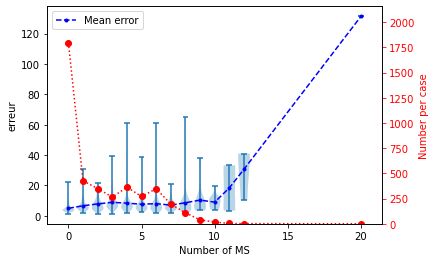

data_scale_7


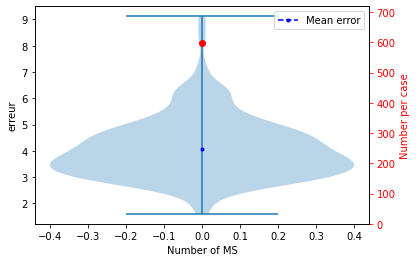

data_scale_8


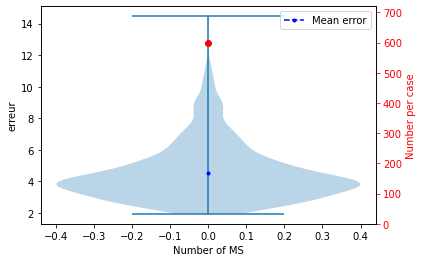

data_scale_9


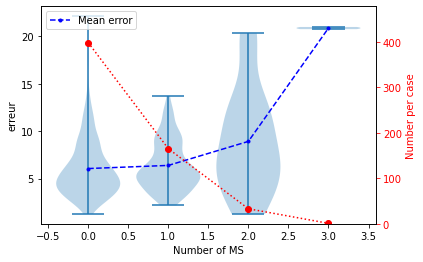

data_scale_10


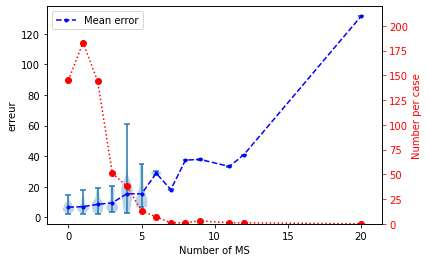

data_scale_11


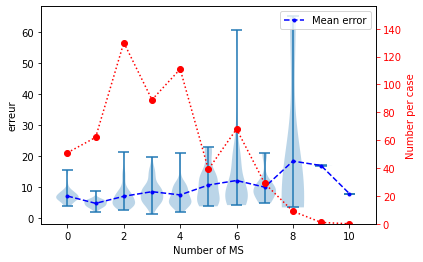

data_scale_12


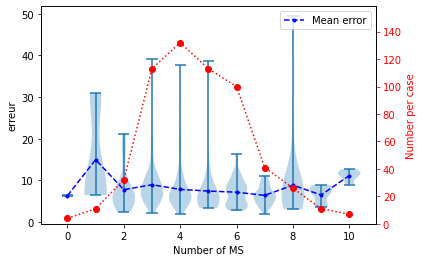

data_scale_13


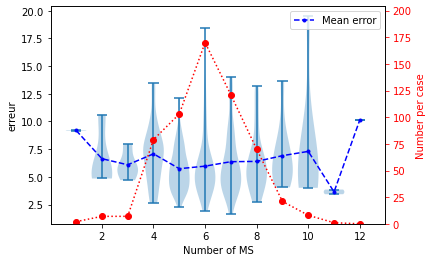

In [5]:

def err_per_number_of_ms(data: dict[Test], eoi:tuple=(0,3), step:float=0.9, width:float=0.1) -> None:
    x_scatter, y_scatter = [], []
    for _, test in data.items():
        err = test.global_err[eoi[0]][eoi[1]]
        number_missing_support = sum([len(i) for i in test.skipped_cyl])
        x_scatter.append(number_missing_support)
        y_scatter.append(err)

    X_sorted, Y_sorted = (list(t) for t in zip(*sorted(zip(x_scatter, y_scatter))))
    old = X_sorted[0]
    X_bulk, Y_bulk, number_per_x= [old], [[]], []
    counter=0
    for x, y in zip(X_sorted, Y_sorted):
        if x<old+step:
            Y_bulk[-1].append(y)
            counter+=1
            continue
        number_per_x.append(counter)
        X_bulk.append(x)
        Y_bulk.append([y])
        old = x
        counter=0
    number_per_x.append(counter)
    y_mean = []
    for y in Y_bulk:
        y_mean.append(np.mean(np.array(y)))
    y_mean = np.array(y_mean)

    plt.violinplot(Y_bulk, X_bulk,widths=width,
                   showmeans=False, showmedians=False, showextrema=True)
    plt.plot(X_bulk, y_mean, '.b--', label='Mean error')
    plt.xlabel(f'Number of MS')
    plt.ylabel('erreur')
    plt.legend()
    ax2=plt.twinx()
    ax2.set_ylim(bottom=0, top=1.2*np.max(number_per_x))
    ax2.plot(X_bulk, number_per_x, 'ro:')
    ax2.set_ylabel('Number per case', color='r')
    ax2.tick_params(axis='y', colors='red')
    plt.show()

to_plot=['data', 'data_scale_7','data_scale_8', 'data_scale_9', 'data_scale_10', 
         'data_scale_11', 'data_scale_12', 'data_scale_13']
#to_plot=['data']

for i in to_plot:
    print(i)
    err_per_number_of_ms(eval(i), width=0.8)

honey_7_6_6_4
1.6


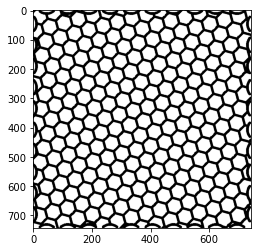

In [6]:

best_t=get_best_test(data_scale_7,number=1)
# %matplotlib qt 
for t in best_t:
    print(t.test_id)
    print(t.global_err[0][3])
    t.show_geo()


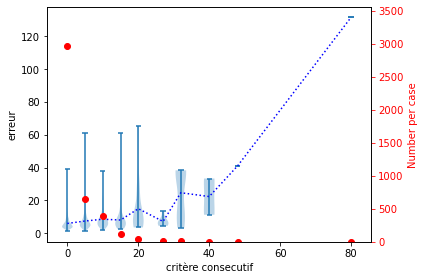

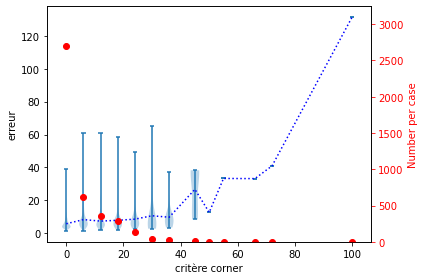

In [7]:

eoi=(0,3)

err=[]
criteria=[]
for _,test in data.items():
    err.append(test.get_err(eoi))
    criteria.append(get_max_MS_consecutive(test))

plot_box2(criteria,err, step=5, ylabel=f'critère consecutif', width=3)
    

def get_mean_MS_worse_corner2(test: Test) -> float:
    mat_MS = test.get_MS()
    mat_MS_corner = test.get_MS_corner()
    return np.max(2*np.sum(mat_MS_corner, axis=1))*test.get_number_ms()

err=[]
criteria=[]
for _,test in data.items():
    err.append(test.get_err(eoi))
    criteria.append(get_mean_MS_worse_corner2(test))

plot_box2(criteria,err, step=5, ylabel=f'critère corner', width=3)

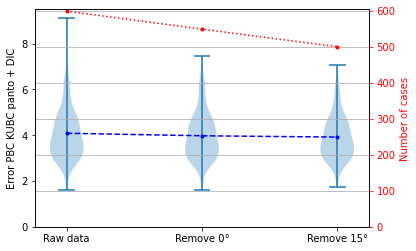

WORSE
honey_7_3_4_2
7.08


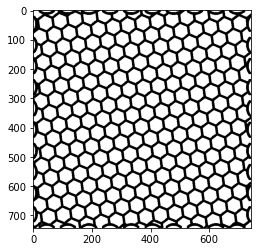

honey_7_9_0_4
7.05


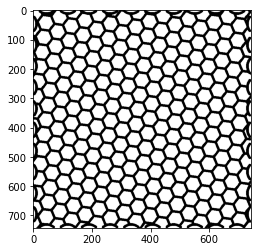

BEST
honey_7_8_0_3
1.73


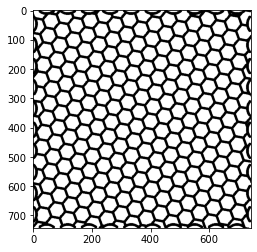

honey_7_8_5_2
1.74


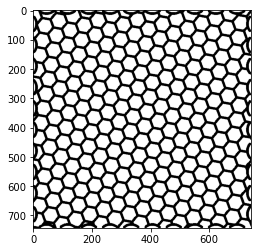

In [8]:

data_raw = data_scale_7
data_list = [[], [], []]
last_tests_dict={}
eoi = (0, 3)
for test_id, test in data_raw.items():
    # * list of conditions
    stage = 0
    data_list[stage].append(test.global_err[eoi[0]][eoi[1]])

    if test.test_id.split('_')[2] in ['0']:  # * Si l'angle est de 0 ou 15°
        continue
    stage += 1
    data_list[stage].append(test.global_err[eoi[0]][eoi[1]])

    if test.test_id.split('_')[2] in ['6']:
        continue
    stage += 1
    data_list[stage].append(test.global_err[eoi[0]][eoi[1]])
    last_tests_dict |= {test_id:test}


plt.figure()
plt.violinplot(data_list, range(len(data_list)), widths=0.25,
               showmeans=False, showmedians=False, showextrema=True)

plt.plot(range(len(data_list)), [np.mean(np.array(i)) for i in data_list], 'b.--')

plt.xticks(range(len(data_list)), ['Raw data', 'Remove 0°', 'Remove 15°'])
plt.ylim(bottom=0.0)
plt.ylabel('Error PBC KUBC panto + DIC')
plt.twinx()
plt.plot(range(len(data_list)), [len(i) for i in data_list], 'r.:')
plt.ylabel('Number of cases', color='r')
plt.tick_params(axis='y', colors='red')
plt.ylim(bottom=0.0)
plt.grid()
plt.show()

print('WORSE')
wb_tests=get_worse_test(last_tests_dict,number=2)
for t in wb_tests:
    print(t.test_id)
    print(t.global_err[0][3])
    t.show_geo()

print('BEST')
wb_tests=get_best_test(last_tests_dict,number=2)
for t in wb_tests:
    print(t.test_id)
    print(t.global_err[0][3])
    t.show_geo()

## Effet des CC

Etude de l'effet des CC sur le NIDA taille 7/10

Lecture des données réalisée en 0.06340s


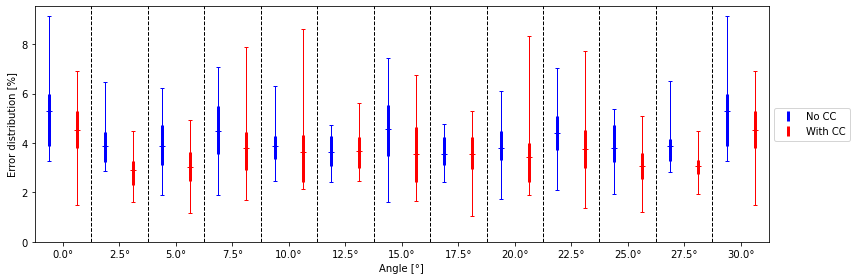

In [9]:
data_no_CC = data_scale_7
data_CC = get_bulk_data(read_data_from_campaigns(['campagne_honey_CC']))

bulk_data = data_no_CC | data_CC


N_theta, N_type, N_tx, N_ty = (12, 2, 10, 5)
EOI = (0, 3)

error_per_angle = np.empty((N_theta+1, N_type, N_tx, N_ty))
error_per_angle[:] = np.nan
for test_id, test in bulk_data.items():
    scale, angle, idx, idy = tuple(map(int, test_id.split('_')[1:]))
    if test_id.split('_')[0][-1]=='C':
        cc=1
    else:
        cc=0

    error_per_angle[angle, cc, idx,
                    idy] = test.global_err[EOI[0]][EOI[1]]
    if angle == 0:
        error_per_angle[-1, cc, idx,
                        idy] = test.global_err[EOI[0]][EOI[1]]

error_per_angle_mean = np.nanmean(error_per_angle, axis=(2, 3))
error_per_angle_q1 = np.nanquantile(error_per_angle, 0.25, axis=(2, 3))
error_per_angle_q2 = np.nanquantile(error_per_angle, 0.75, axis=(2, 3))
error_per_angle_min = np.nanmin(error_per_angle, axis=(2, 3))
error_per_angle_max = np.nanmax(error_per_angle, axis=(2, 3))

plt.figure(figsize=(12, 4))
x = np.linspace(0, N_theta, N_theta+1)-0.5+1/N_type/2
col = ['b', 'r', 'r', 'm', 'k', 'c', 'y']
leg = ['No CC', 'With CC']

for scale in range(N_type):
    plt.errorbar(x+scale/N_type, error_per_angle_mean[:, scale], [error_per_angle_mean[:, scale]-error_per_angle_q1[:, scale], error_per_angle_q2[:, scale] - error_per_angle_mean[:, scale]],
                 fmt=col[scale]+'_', lw=3, ms=1, label=f'{leg[scale]}')
    plt.errorbar(x+scale/N_type, error_per_angle_mean[:, scale], [error_per_angle_mean[:, scale]-error_per_angle_min[:, scale], error_per_angle_max[:, scale] - error_per_angle_mean[:, scale]],
                 fmt='_'+col[scale], ecolor=col[scale], lw=1, capsize=2)
    for i, m in enumerate(error_per_angle_max[:, scale]):
        if m > 30.0:
            plt.text(x[i]+scale/N_type,
                     30.0, f'{m:.0f}', ha='center', fontsize=8)

for i in range(12):
    plt.axvline(x=i+0.5, color='k', ls='--', lw=1.0)

plt.ylim(bottom=0)
plt.xlim((-0.5, 12.5))
plt.xticks(range(13), [f'{2.5*i}°' for i in range(13)])
plt.legend()
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('Angle [°]')
plt.ylabel(f'Error distribution [%]')
plt.tight_layout()
plt.show()

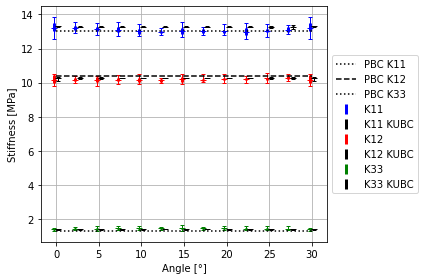

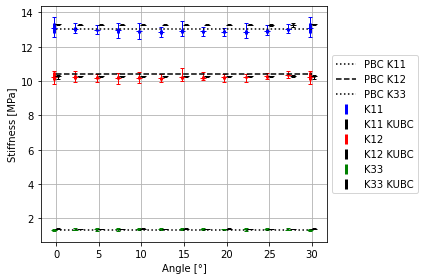

In [10]:
plot_coef_matrix_per_angle(data_scale_7, (12, 7, 10, 5), angle_max=30.0)
plot_coef_matrix_per_angle(data_CC, (12, 7, 10, 5), angle_max=30.0)

Les CC semble surtout amélioirer la mesure du coef K33 de la matrice de rigidité

In [11]:
coefs=((0,0),(1,0),(2,2))
for coef in coefs:
    K33_dev_mean_noCC=0.0
    for _,test in data_no_CC.items():
        k33=test.K_panto_dic[coef[0]][coef[1]]
        k33_pbc=test.K_plane_stress_PBC[coef[0]][coef[1]]
        K33_dev_mean_noCC += abs(k33-k33_pbc)/k33_pbc
    K33_dev_mean_noCC=K33_dev_mean_noCC/len(data_no_CC)*100

    K33_dev_mean_CC=0.0
    for _,test in data_CC.items():
        k33=test.K_panto_dic[coef[0]][coef[1]]
        k33_pbc=test.K_plane_stress_PBC[coef[0]][coef[1]]
        K33_dev_mean_CC += abs(k33-k33_pbc)/k33_pbc
    K33_dev_mean_CC=K33_dev_mean_CC/len(data_CC)*100

    print(f'Erreur moyenne [%] {coef=}: \nNo CC: {K33_dev_mean_noCC:.1f}\nCC:    {K33_dev_mean_CC:.1f}')

Erreur moyenne [%] coef=(0, 0): 
No CC: 1.3
CC:    1.3
Erreur moyenne [%] coef=(1, 0): 
No CC: 2.1
CC:    1.9
Erreur moyenne [%] coef=(2, 2): 
No CC: 11.4
CC:    5.1


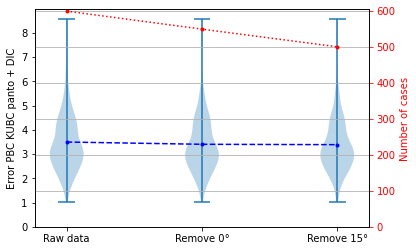

In [12]:

data_raw = data_CC
data_list = [[], [], []]
last_tests_dict={}
eoi = (0, 3)
for test_id, test in data_raw.items():
    # * list of conditions
    stage = 0
    data_list[stage].append(test.global_err[eoi[0]][eoi[1]])

    if test.test_id.split('_')[2] in ['0']:  # * Si l'angle est de 0 ou 15°
        continue
    stage += 1
    data_list[stage].append(test.global_err[eoi[0]][eoi[1]])

    if test.test_id.split('_')[2] in ['6']:
        continue
    stage += 1
    data_list[stage].append(test.global_err[eoi[0]][eoi[1]])
    last_tests_dict |= {test_id:test}


plt.figure()
plt.violinplot(data_list, range(len(data_list)), widths=0.25,
               showmeans=False, showmedians=False, showextrema=True)

plt.plot(range(len(data_list)), [np.mean(np.array(i)) for i in data_list], 'b.--')

plt.xticks(range(len(data_list)), ['Raw data', 'Remove 0°', 'Remove 15°'])
plt.ylim(bottom=0.0)
plt.ylabel('Error PBC KUBC panto + DIC')
plt.twinx()
plt.plot(range(len(data_list)), [len(i) for i in data_list], 'r.:')
plt.ylabel('Number of cases', color='r')
plt.tick_params(axis='y', colors='red')
plt.ylim(bottom=0.0)
plt.grid()
plt.show()

# print('WORSE')
# wb_tests=get_worse_test(last_tests_dict,number=1)
# for t in wb_tests:
#     print(t.test_id)
#     print(t.global_err[0][3])
#     t.show_geo()

# print('BEST')
# wb_tests=get_best_test(last_tests_dict,number=1)
# for t in wb_tests:
#     print(t.test_id)
#     print(t.global_err[0][3])
#     t.show_geo()

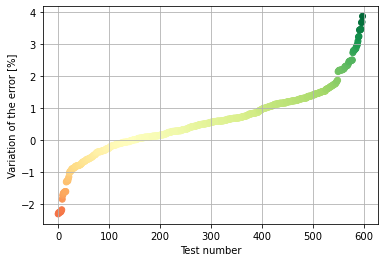

Amélioration moyenne : 0.5891652754590984
Tests pour qui ca a le mieux marché
honeyCC_7_0_5_0 avec un évolution de 3.88


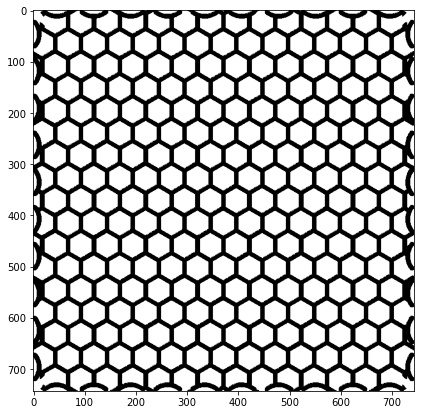

Tests pour qui ca a le moins bien marché
honeyCC_7_4_7_4 avec un évolution de -2.3


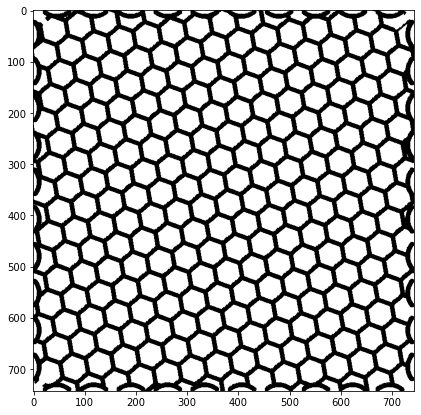

In [13]:
""" Understand whyl in some cases the CC is better and sometime no"""
# data_CC
# data_no_CC
changes=[]
names=[]
eoi=(0,3)
for test_id,test in data_CC.items():
    changes.append(-test.global_err[eoi[0]][eoi[1]]+data_no_CC[test_id[:5]+test_id[7:]].global_err[eoi[0]][eoi[1]])
    names.append(test_id)


changes, names=[list(i) for i in zip(*sorted(zip(changes, names)))]

plt.scatter(range(len(changes)), changes,c=changes, cmap='RdYlGn', vmin=min([min(changes),-max(changes)]))
plt.grid()
plt.xlabel('Test number')
plt.ylabel('Variation of the error [%]')
plt.show()


N=1
print(f'Amélioration moyenne : {np.mean(np.asarray(changes))}')
print('Tests pour qui ca a le mieux marché')
for name, val in zip(names[-N:],changes[-N:]):
    print(f'{name} avec un évolution de {val}')
    plt.figure(figsize=(7,7))
    data_CC[name].show_geo()

print('Tests pour qui ca a le moins bien marché')
for name, val in zip(names[:N],changes[:N]):
    print(f'{name} avec un évolution de {val}')
    plt.figure(figsize=(7,7))
    data_CC[name].show_geo()



# Etude de l'effet lié à la libre rotation des cylindres

Lecture des données réalisée en 0.05596s


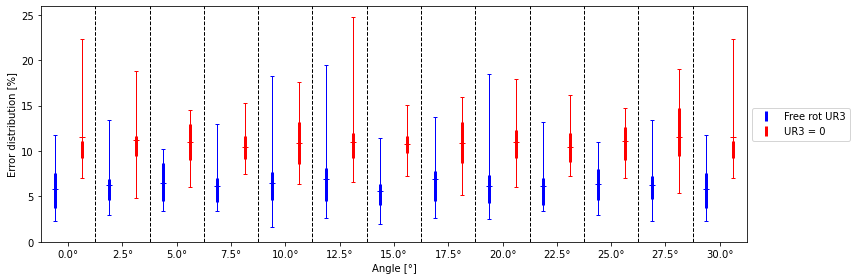

In [14]:
data_scale_13_UR3 = get_bulk_data(read_data_from_campaigns(['campagne_honey_UR3']))


bulk_data = data_scale_13 | data_scale_13_UR3


N_theta, N_type, N_tx, N_ty = (12, 2, 10, 5)
EOI = (0, 3)

error_per_angle = np.empty((N_theta+1, N_type, N_tx, N_ty))
error_per_angle[:] = np.nan
for test_id, test in bulk_data.items():
    scale, angle, idx, idy = tuple(map(int, test_id.split('_')[1:]))
    
    if test_id.split('_')[0][-1]=='3':
        cc=1
    else:
        cc=0

    error_per_angle[angle, cc, idx,
                    idy] = test.global_err[EOI[0]][EOI[1]]
    if angle == 0:
        error_per_angle[-1, cc, idx,
                        idy] = test.global_err[EOI[0]][EOI[1]]

error_per_angle_mean = np.nanmean(error_per_angle, axis=(2, 3))
error_per_angle_q1 = np.nanquantile(error_per_angle, 0.25, axis=(2, 3))
error_per_angle_q2 = np.nanquantile(error_per_angle, 0.75, axis=(2, 3))
error_per_angle_min = np.nanmin(error_per_angle, axis=(2, 3))
error_per_angle_max = np.nanmax(error_per_angle, axis=(2, 3))

plt.figure(figsize=(12, 4))
x = np.linspace(0, N_theta, N_theta+1)-0.5+1/N_type/2
col = ['b', 'r', 'r', 'm', 'k', 'c', 'y']
leg = ['Free rot UR3', 'UR3 = 0']

for scale in range(N_type):
    plt.errorbar(x+scale/N_type, error_per_angle_mean[:, scale], [error_per_angle_mean[:, scale]-error_per_angle_q1[:, scale], error_per_angle_q2[:, scale] - error_per_angle_mean[:, scale]],
                 fmt=col[scale]+'_', lw=3, ms=1, label=f'{leg[scale]}')
    plt.errorbar(x+scale/N_type, error_per_angle_mean[:, scale], [error_per_angle_mean[:, scale]-error_per_angle_min[:, scale], error_per_angle_max[:, scale] - error_per_angle_mean[:, scale]],
                 fmt='_'+col[scale], ecolor=col[scale], lw=1, capsize=2)
    for i, m in enumerate(error_per_angle_max[:, scale]):
        if m > 30.0:
            plt.text(x[i]+scale/N_type,
                     30.0, f'{m:.0f}', ha='center', fontsize=8)

for i in range(12):
    plt.axvline(x=i+0.5, color='k', ls='--', lw=1.0)

plt.ylim(bottom=0)
plt.xlim((-0.5, 12.5))
plt.xticks(range(13), [f'{2.5*i}°' for i in range(13)])
plt.legend()
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('Angle [°]')
plt.ylabel(f'Error distribution [%]')
plt.tight_layout()
plt.show()


In [68]:
%matplotlib 

test = data[list(data.keys())[0]]
img = test.get_geo()


DIST_FROM_EDGE = 10.0
SMALL_RADIUS = 13.0
BIG_RADIUS = 16.0
DIST_FROM_CORNER_EDGE = 18.0
PAS = 28.0
L = 288.0

PIC_SIZE = 743  # square shape
SCALE = PIC_SIZE/L


def get_circle(center, radius: float) -> list[list]:
    center = np.array(center)
    l = []
    N = 500
    for i in range(N):
        x = int(center[0]+radius*cos(2*pi*i/N))
        y = int(center[1]+radius*sin(2*pi*i/N))
        if [x, y] not in l and x >= 0 and y >= 0 and x < PIC_SIZE and y < PIC_SIZE:
            l.append([x, y])
    return l


def init_pix():
    centers = np.zeros((4, 10, 2))
    for cote in range(4):
        for cyl in range(10):
            if cote % 2 == 1:
                x = - cyl*PAS*SCALE + (L-DIST_FROM_CORNER_EDGE)*SCALE
                y = L*SCALE+DIST_FROM_EDGE*SCALE if cote == 1 else -DIST_FROM_EDGE*SCALE
            else:
                x = L*SCALE+DIST_FROM_EDGE*SCALE if cote == 0 else -DIST_FROM_EDGE*SCALE
                y = cyl*PAS*SCALE + DIST_FROM_CORNER_EDGE*SCALE
            centers[cote, cyl, :] = np.array([int(x), int(y)])
    return centers


def draw_circle(img, pix_list, val=0.0):
    for p in pix_list:
        img[p[0], p[1]] = val
    return img


centers = init_pix()
img2 = img.copy()
for co in range(4):
    for cy in range(10):
        if cy in test.skipped_cyl[co]:
            val = 1.0
        else:
            val = 0.0
        img2 = draw_circle(img2, get_circle(
            centers[co, cy, :], SCALE*BIG_RADIUS), val=val)


plt.figure(figsize=(10, 10))
plt.imshow(img2)
plt.show()

#~ Trier pix_list et peut etre créer une list avec pix_list dedans

Using matplotlib backend: TkAgg


In [ ]:

#~ faire tourner le meme calcul avec le 7/10 pour montrer que ca a moins d'importance à cette échelle?